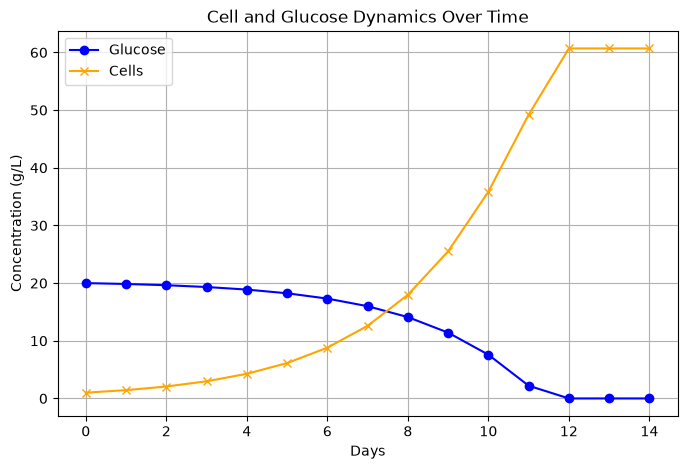

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
cells = np.empty(len(days))


# Initial conditions
glucose[0] = 20.0  # g/L
initial_cells = 1.0      # million cells/mL
cells[0] = initial_cells
glucose_consumption_rate = 0.15  # g/L per million cells per day
dt = 1.0  # time step in days

mu_max = 0.4 # g/L 
Ks = 2.0 # g/L

# Simple exponential growth model
for j in range(1, len(days)):
    mu = mu_max * glucose[j-1] / (Ks + glucose[j-1])  # Monod equation for growth rate
    cells[j] = cells[j-1] * np.exp(mu * dt)  # Cell growth
    glucose[j] = glucose[j-1] - (glucose_consumption_rate * cells[j-1] * dt)  # Glucose consumption
    if glucose[j] < 0:
        glucose[j] = 0  # Prevent negative glucose concentration

plt.figure(figsize=(8,5))
plt.plot(days, glucose, marker="o", label="Glucose", color='blue')
plt.plot(days, cells, marker="x", label="Cells", color='orange')
plt.title("Cell and Glucose Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

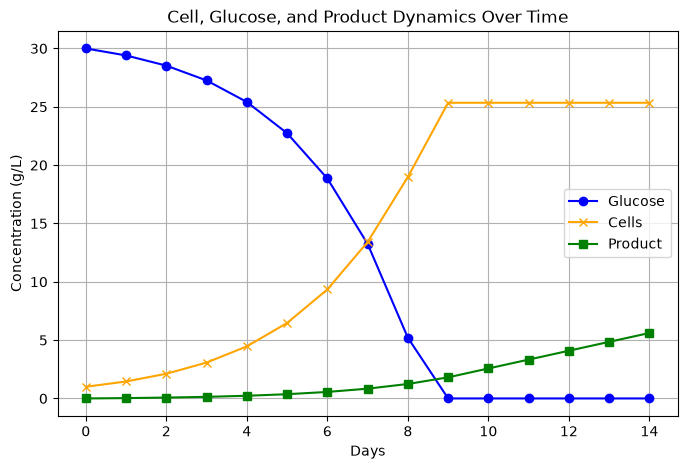

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
cells = np.empty(len(days))
product = np.empty(len(days))


# Initial conditions
glucose[0] = 30.0  # g/L
initial_cells = 1.0      # million cells/mL
cells[0] = initial_cells
product[0] = 0.0  # g/L

mu_max = 0.4 # 1/day 
Ks = 2.0 # g/L
qG = 600.0  # picograms / (cell . day)
dt = 1.0  # time step in days
qp = 30.0  # picograms / (cell . day)

# Simple exponential growth model
for i in range(1, len(days)):
    mu = mu_max * glucose[i-1] / (Ks + glucose[i-1])  # Monod equation for growth rate
    cells_per_L = cells[i-1] * 1e9  # million cells/mL to cells/L conversion factor
    glucose[i] = glucose[i-1] - (qG * cells_per_L * 1e-12 * dt)  # Glucose consumption
    product[i] = product[i-1] + (qp * cells_per_L * 1e-12 * dt)  # Product formation
    cells[i] = cells[i-1] * np.exp(mu * dt)  # Cell growth
    glucose[i] = max(glucose[i], 0)  # Prevent negative glucose concentration

plt.figure(figsize=(8,5))
plt.plot(days, glucose, marker="o", label="Glucose", color='blue')
plt.plot(days, cells, marker="x", label="Cells", color='orange')
plt.plot(days, product, marker="s", label="Product", color='green')
plt.title("Cell, Glucose, and Product Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

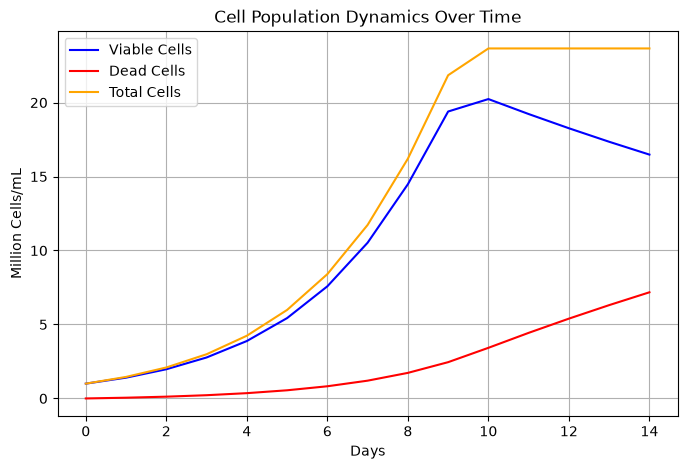

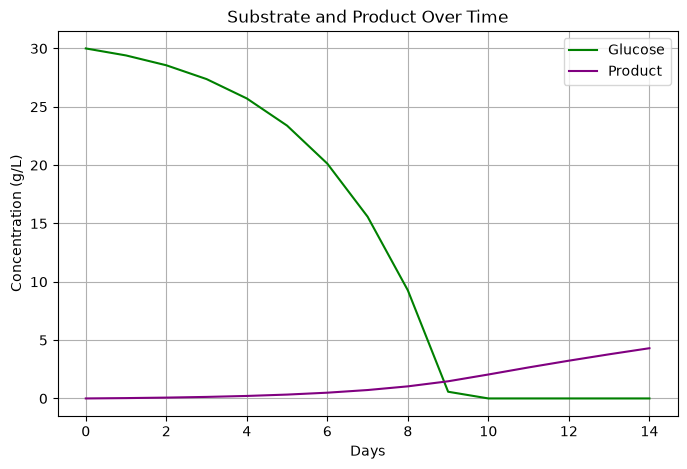

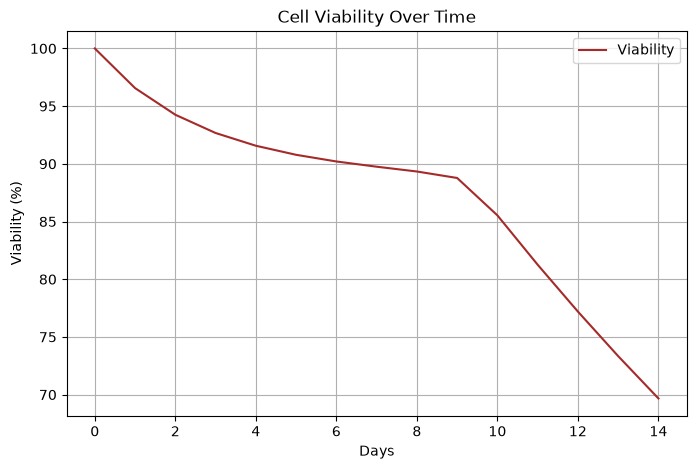

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation settings
days = np.arange(0, 15, 1)
glucose = np.empty(len(days))
product = np.empty(len(days))
viable_cells = np.empty(len(days))
dead_cells = np.empty(len(days))


# Initial conditions
glucose[0] = 30.0  # g/L
initial_cells = 1.0      # million cells/mL
viable_cells[0] = initial_cells
dead_cells[0] = 0.0
product[0] = 0.0  # g/L

mu_max = 0.4 # 1/day 
Ks = 2.0 # g/L
qG = 600.0  # picograms / (cell . day)
dt = 1.0  # time step in days
qp = 30.0  # picograms / (cell . day)

#cell viability parameters
k_d = 0.05  # death rate constant (1/day)

#Cell Viability Model
for i in range(1, len(days)):
    mu = mu_max * glucose[i-1] / (Ks + glucose[i-1])  # Monod equation for growth rate
    cells_per_L = viable_cells[i-1] * 1e9  # million cells/mL to cells/L conversion factor
    glucose[i] = glucose[i-1] - (qG * cells_per_L * 1e-12 * dt)  # Glucose consumption
    glucose[i] = max(glucose[i], 0)  # Prevent negative glucose concentration
    product[i] = product[i-1] + (qp * cells_per_L * 1e-12 * dt)  # Product formation
    dead_today = k_d * viable_cells[i-1] * dt  # Number of cells that die today
    new_cells = viable_cells[i-1] * (np.exp(mu * dt) - 1)  # New viable cells produced
    viable_cells[i] = viable_cells[i-1] + new_cells - dead_today  # Viable cell growth and death
    viable_cells[i] = max(viable_cells[i], 0)
    dead_cells[i] = dead_cells[i-1] + dead_today  # Accumulation of dead cells

total_cells = viable_cells + dead_cells
viability = (viable_cells / total_cells) * 100

#Figure 1
plt.figure(figsize=(8,5))
plt.plot(days, viable_cells, label = "Viable Cells", color='blue')
plt.plot(days, dead_cells, label = "Dead Cells", color='red')
plt.plot(days, total_cells, label = "Total Cells", color='orange')
plt.title("Cell Population Dynamics Over Time")
plt.xlabel("Days")
plt.ylabel("Million Cells/mL")
plt.legend()
plt.grid()
plt.show()

#Figure 2
plt.figure(figsize=(8,5))
plt.plot(days, glucose, label = "Glucose", color='green')
plt.plot(days, product, label = "Product", color='purple')
plt.title("Substrate and Product Over Time")
plt.xlabel("Days")
plt.ylabel("Concentration (g/L)")
plt.legend()
plt.grid()
plt.show()

#Figure 3
plt.figure(figsize=(8,5))
plt.plot(days, viability, label = "Viability", color='brown')
plt.title("Cell Viability Over Time")
plt.xlabel("Days")  
plt.ylabel("Viability (%)")
plt.legend()
plt.grid()  
plt.show()